# 01 · Data Quality Assessment & Cleaning
ผู้รับผิดชอบ: สมาชิก A (B ช่วยตรวจปี 2569)

สร้างไฟล์กลางที่ทุกข้อใช้ร่วมกัน:
- `data/prepared/passengers_clean_long.csv` — ข้อมูลทั้งสองปี 1 แถว = 1 บริการ × 1 วัน พร้อม flag คุณภาพ
- `data/prepared/service_catalog.csv` — Data Dictionary ของ 43 บริการ (หน่วย, ทิศ, ยอดรวม, เหตุผลที่ตัด)
- `data/prepared/quality_log.csv` — จำนวนแถว/ค่าว่าง/ค่าซ้ำ/ค่าศูนย์ ก่อน-หลัง

**หลักการ:** ไม่เติมค่าว่างและไม่ลบค่าศูนย์ในไฟล์กลาง แต่ติด flag ไว้ แต่ละข้อจะเลือกวิธีจัดการเองพร้อมเหตุผล (ข้อ 2 ต้องทดสอบหลายวิธี)

In [19]:
import sys
import importlib
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import prep
importlib.reload(prep)  # pick up edits to src/prep.py without restarting the kernel

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
prep.setup_thai_font()  # should print 'Sukhumvit Set'

'Sukhumvit Set'

## 1. โหลดและตัดแถวว่าง

In [20]:
rows_in_file = {}
raw = {}
for y, path in prep.RAW_FILES.items():
    rows_in_file[y] = len(pd.read_csv(path, encoding="utf-8-sig", dtype=str, keep_default_na=False))
    raw[y] = prep.load_raw(path)
    print(f"{y}: {rows_in_file[y]:,} rows in file -> {len(raw[y]):,} after removing blank rows")

2568: 69,440 rows in file -> 15,696 after removing blank rows
2569: 3,010 rows in file -> 3,010 after removing blank rows


## 2. Cleaning pipeline (`src/prep.py::clean`)
| ขั้น | สิ่งที่ทำ | เหตุผล |
|---|---|---|
| 1 | แปลงวันที่ `%d/%m/%Y` (ค.ศ.), ลบ comma ในปริมาณแล้วแปลงเป็น float | ไฟล์เก็บทุกอย่างเป็นข้อความ |
| 2 | แก้ชื่อ “ท่าอากาศอื่น ๆ ของ ทอท.” → “ท่าอากาศยานอื่น ๆ ของ ทอท.” | ชื่อเดียวกันสะกดสองแบบ |
| 3 | ตัดแถวซ้ำ key (service, date) ที่ค่าเท่ากัน (ถ้าค่าต่างกันโค้ดจะหยุดทำงาน) | ป้องกันการนับซ้ำ |
| 4 | แยก `port` และ `direction` จากคำว่า ขาเข้า/ขาออกประเทศ | ข้อ 3 ต้องเทียบขาเข้า vs ขาออก |
| 5 | ติด `missing_flag`, `zero_flag`, `zero_run_len`, `zero_long_run` (ศูนย์ติดกัน ≥ 7 วัน) | แยก “ไม่ได้รายงาน” ออกจาก “ศูนย์จริง” |
| 6 | `is_aggregate` = รายการ “รถยนต์ทุกประเภท” | รวมรถ 4 ล้อไว้แล้ว ห้ามบวกซ้ำ |
| 7 | `exclude_reason`: หน่วย “คัน” หรือเป็นศูนย์ทุกวันทั้งสองปี | ไม่ใช่ข้อมูลผู้โดยสารที่ใช้ได้ |

In [21]:
clean_df, catalog = prep.clean(raw)
print(clean_df.shape)
clean_df.head()

(18705, 18)


,date,year_be,mode,purpose,public_private,agency,service,port,direction,unit,is_aggregate,exclude_reason,value,missing_flag,zero_flag,zero_run_len,zero_long_run,had_duplicate
0,2025-01-01,2568,air,intercity,สาธารณะ,ทอท.,ท่าอากาศยานดอนเมือง,ท่าอากาศยานดอนเมือง,none,คน,False,,31842.0,False,False,0,False,False
1,2025-01-02,2568,air,intercity,สาธารณะ,ทอท.,ท่าอากาศยานดอนเมือง,ท่าอากาศยานดอนเมือง,none,คน,False,,32333.0,False,False,0,False,False
2,2025-01-03,2568,air,intercity,สาธารณะ,ทอท.,ท่าอากาศยานดอนเมือง,ท่าอากาศยานดอนเมือง,none,คน,False,,34067.0,False,False,0,False,False
3,2025-01-04,2568,air,intercity,สาธารณะ,ทอท.,ท่าอากาศยานดอนเมือง,ท่าอากาศยานดอนเมือง,none,คน,False,,34798.0,False,False,0,False,False
4,2025-01-05,2568,air,intercity,สาธารณะ,ทอท.,ท่าอากาศยานดอนเมือง,ท่าอากาศยานดอนเมือง,none,คน,False,,33342.0,False,False,0,False,False


## 3. Quality log ก่อน → หลัง (ใช้ในรายงานส่วนที่ 2 และสไลด์)

In [22]:
quality_log = prep.quality_report(raw, rows_in_file, clean_df)
quality_log.T

,0,1
year_be,2568,2569
rows_in_file,69440,3010
blank_rows_removed,53744,0
rows_after_blank_removal,15696,3010
duplicate_rows_removed,1,0
rows_clean,15695,3010
n_services,43,43
first_date,2025-01-01,2026-01-01
last_date,2025-12-31,2026-03-11
n_days,365,70


## 4. Service catalog

In [23]:
catalog

,service,port,direction,mode,purpose,public_private,agency,unit,n_days,n_missing,n_zero,n_zero_long_run,mean_value,is_aggregate,exclude_reason
0,ท่าอากาศยานดอนเมือง,ท่าอากาศยานดอนเมือง,none,air,intercity,สาธารณะ,ทอท.,คน,435,0,0,0,2.762081e+04,False,
1,ท่าอากาศยานภูมิภาค,ท่าอากาศยานภูมิภาค,none,air,intercity,สาธารณะ,ทย.,คน,435,0,0,0,1.973721e+04,False,
2,ท่าอากาศยานสมุย,ท่าอากาศยานสมุย,none,air,intercity,สาธารณะ,กพท.,คน,435,0,2,0,3.640880e+03,False,
3,ท่าอากาศยานสุวรรณภูมิ,ท่าอากาศยานสุวรรณภูมิ,none,air,intercity,สาธารณะ,ทอท.,คน,435,0,0,0,1.735584e+04,False,
4,ท่าอากาศยานอื่น ๆ ของ ทอท.,ท่าอากาศยานอื่น ๆ ของ ทอท.,none,air,intercity,สาธารณะ,ทอท.,คน,435,0,0,0,2.593807e+04,False,
5,ท่าอากาศยานอู่ตะเภา,ท่าอากาศยานอู่ตะเภา,none,air,intercity,สาธารณะ,กพท.,คน,435,0,2,0,2.268460e+02,False,
6,รถไฟ,รถไฟ,none,rail,intercity,สาธารณะ,รฟท.,คน,435,1,2,0,7.527229e+04,False,
7,รถ บขส. และ รถร่วม,รถ บขส. และ รถร่วม,none,road,intercity,สาธารณะ,บขส.,คน,435,2,0,0,9.175384e+04,False,
8,รถยนต์ทุกประเภท (10 จุดสำรวจ),รถยนต์ทุกประเภท (10 จุดสำรวจ),none,road,intercity,ส่วนบุคคล,ทล.,คัน,435,208,0,0,9.765738e+05,True,unit=คัน (not passengers)
9,รถยนต์ทุกประเภท (ทางด่วน),รถยนต์ทุกประเภท (ทางด่วน),none,road,intercity,ส่วนบุคคล,กทพ.,คัน,435,0,0,0,1.567834e+06,True,unit=คัน (not passengers)


In [24]:
print("บริการที่ถูกตัดออกจากการรวมยอดผู้โดยสาร:")
display(catalog.loc[catalog["exclude_reason"] != "", ["service", "unit", "exclude_reason"]])
print("รายการยอดรวม (is_aggregate):", catalog.loc[catalog["is_aggregate"], "service"].tolist())

บริการที่ถูกตัดออกจากการรวมยอดผู้โดยสาร:


,service,unit,exclude_reason
8,รถยนต์ทุกประเภท (10 จุดสำรวจ),คัน,unit=คัน (not passengers)
9,รถยนต์ทุกประเภท (ทางด่วน),คัน,unit=คัน (not passengers)
10,รถยนต์เฉพาะ 4 ล้อ (10 จุดสำรวจ),คัน,unit=คัน (not passengers)
11,รถยนต์เฉพาะ 4 ล้อ (ทางด่วน),คัน,unit=คัน (not passengers)
34,รถร่วม (หมวด 1),คน,all-zero series (not reported)


รายการยอดรวม (is_aggregate): ['รถยนต์ทุกประเภท (10 จุดสำรวจ)', 'รถยนต์ทุกประเภท (ทางด่วน)']


## 5. แผนภาพความครบถ้วน: สัดส่วนวันที่เป็นค่าว่างหรือศูนย์ ต่อบริการ × เดือน

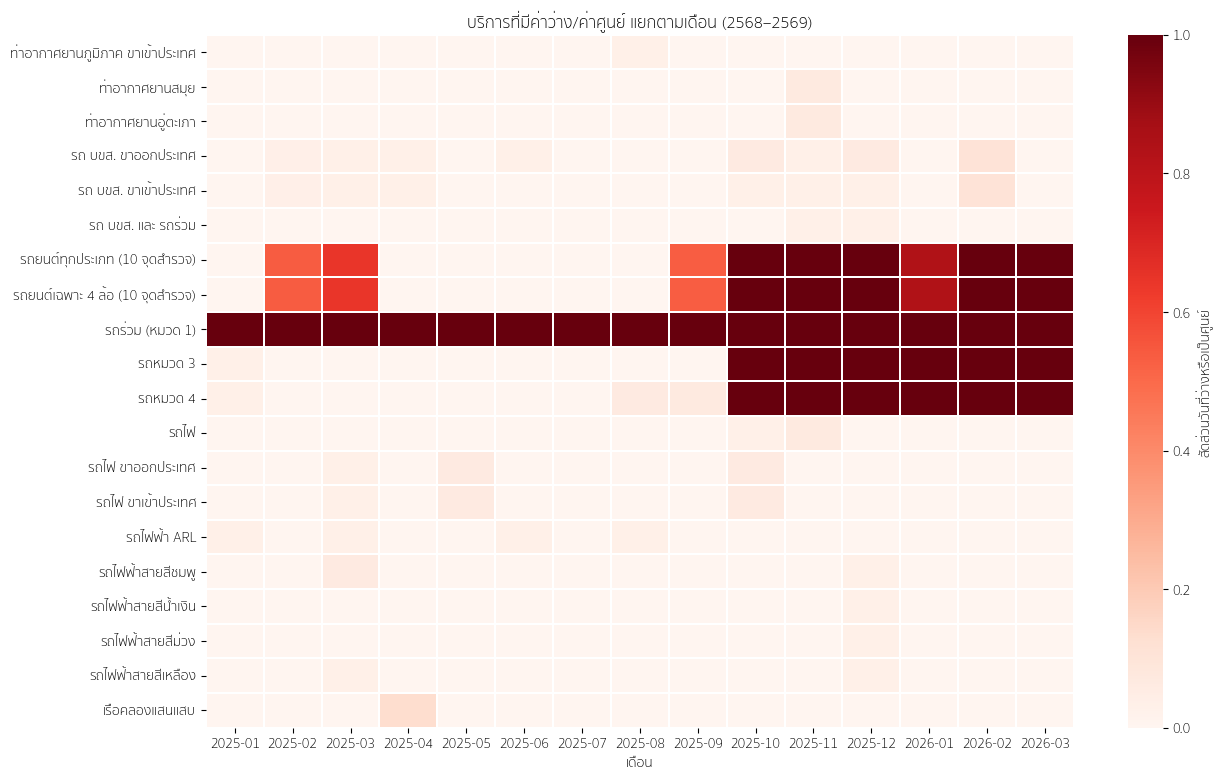

In [25]:
tmp = clean_df.assign(month=clean_df["date"].dt.to_period("M").astype(str),
                     problem=clean_df["missing_flag"] | clean_df["zero_flag"])
heat = tmp.pivot_table(index="service", columns="month", values="problem", aggfunc="mean")
heat = heat[heat.sum(axis=1) > 0]

fig, ax = plt.subplots(figsize=(14, 0.35 * len(heat) + 2))
sns.heatmap(heat, cmap="Reds", vmin=0, vmax=1, linewidths=0.3, cbar_kws={"label": "สัดส่วนวันที่ว่างหรือเป็นศูนย์"}, ax=ax)
ax.set_title("บริการที่มีค่าว่าง/ค่าศูนย์ แยกตามเดือน (2568–2569)")
ax.set_xlabel("เดือน"); ax.set_ylabel("")
prep.save_fig(fig, "01_quality_heatmap")
plt.show()

## 6. บันทึกไฟล์กลาง

In [26]:
prep.PREPARED_DIR.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(prep.PREPARED_DIR / "passengers_clean_long.csv", index=False, encoding="utf-8-sig")
catalog.to_csv(prep.PREPARED_DIR / "service_catalog.csv", index=False, encoding="utf-8-sig")
quality_log.to_csv(prep.PREPARED_DIR / "quality_log.csv", index=False, encoding="utf-8-sig")

# ตรวจว่าอ่านกลับมาได้ค่าเดิม
reloaded = prep.load_clean()
assert len(reloaded) == len(clean_df)
assert np.isclose(reloaded["value"].sum(), clean_df["value"].sum())
print("saved:", [p.name for p in sorted(prep.PREPARED_DIR.glob("*.csv"))])

saved: ['passengers_clean_long.csv', 'quality_log.csv', 'service_catalog.csv']
